# Capítulo 5 · Proyecto 2 · Clasificación de celulares

> ¿Qué características de un celular necesitas para predecir su gama de precio y qué modelo recomendarías a una tienda?

Usa los 2000 equipos etiquetados del archivo `train.csv`. La copia local está en `workspace/chapter_05/datos/mobile_price_train.csv` desde la raíz del repositorio. Documenta tu trabajo de modo que otra persona pueda repetirlo. [Mobile Price Classification](https://www.kaggle.com/iabhishekofficial):

## Etapa 1 · Preparación y selección de características

1. Identifica las 20 características y separa la variable objetivo `price_range`. Sus cuatro valores van de 0 (gama más baja) a 3 (gama más alta).
2. Reserva el 20 % para prueba con una división estratificada y `random_state=42`. En el 80 % de entrenamiento, revisa los valores faltantes, los duplicados y la distribución de las gamas. Justifica las decisiones de limpieza.
3. Antes de entrenar, anota tres características que esperas que ayuden a distinguir las gamas. Elige el algoritmo de selección que prefieras y explica qué criterio utiliza para conservar una característica.

In [194]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.model_selection import KFold
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    ConfusionMatrixDisplay, confusion_matrix, f1_score, roc_auc_score, roc_curve,
)
from scipy.stats.contingency import association
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import (
    RFE, SelectKBest, SequentialFeatureSelector,
    VarianceThreshold, f_classif,
)
from sklearn.linear_model import Lasso, LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from itertools import combinations

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
df = pd.read_csv(raiz / "data" / "Mobile.csv")
df.head()

,Battery_power_mAh,Bluetooh,Speed_of_microprocessor,Dual_sim,Front_camera,4G,Internal_memeory_gb,Mobile_depth,Mobile_weight,Cores_of_processor,...,px_height,Pixel_width,Ram_mb,Screen_height,Screen_weight,talk_time,3G,touch_screen,wifi,price_range
0,842 mAh,No,2.2,No,1 pixels,No,7 gb,0.6 cm,188 g,2,...,20 ppcm,756 ppcm,2549 mb,9 cm,7 cm,19,No,No,Yes,Medium cost
1,1021 mAh,Yes,0.5,Yes,0 pixels,Yes,53 gb,0.7 cm,136 g,3,...,905 ppcm,1988 ppcm,2631 mb,17 cm,3 cm,7,Yes,Yes,No,High cost
2,563 mAh,Yes,0.5,Yes,2 pixels,Yes,41 gb,0.9 cm,145 g,5,...,1263 ppcm,1716 ppcm,2603 mb,11 cm,2 cm,9,Yes,Yes,No,High cost
3,615 mAh,Yes,2.5,No,0 pixels,No,10 gb,0.8 cm,131 g,6,...,1216 ppcm,1786 ppcm,2769 mb,16 cm,8 cm,11,Yes,No,No,High cost
4,1821 mAh,Yes,1.2,No,13 pixels,Yes,44 gb,0.6 cm,141 g,2,...,1208 ppcm,1212 ppcm,1411 mb,8 cm,2 cm,15,Yes,Yes,No,Medium cost


In [195]:
print ("Filas y columnas del dataset: ", df.shape)
df.info()

Filas y columnas del dataset:  (2000, 21)
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Battery_power_mAh        2000 non-null   str    
 1   Bluetooh                 2000 non-null   str    
 2   Speed_of_microprocessor  2000 non-null   float64
 3   Dual_sim                 2000 non-null   str    
 4   Front_camera             2000 non-null   str    
 5   4G                       2000 non-null   str    
 6   Internal_memeory_gb      2000 non-null   str    
 7   Mobile_depth             2000 non-null   str    
 8   Mobile_weight            2000 non-null   str    
 9   Cores_of_processor       2000 non-null   int64  
 10  Primary_camera           2000 non-null   str    
 11  px_height                2000 non-null   str    
 12  Pixel_width              2000 non-null   str    
 13  Ram_mb                   2000 non-null   str   


| Original | Traducción | Descripción |
| --- | --- | --- |
| `Battery_power_mAh` | `capacidad_bateria_mAh` | Energía total que puede almacenar la batería en mAh. |
| `Bluetooh` | `bluetooth` | Indica si cuenta con Bluetooth (`1` sí, `0` no). |
| `Speed_of_microprocessor` | `velocidad_microprocesador` | Velocidad de ejecución de instrucciones del procesador. |
| `Dual_sim` | `doble_sim` | Indica si admite doble tarjeta SIM (`1` sí, `0` no). |
| `Front_camera` | `camara_frontal` | Resolución de la cámara frontal en megapíxeles. |
| `4G` | `4G` | Indica si tiene conectividad 4G (`1` sí, `0` no). |
| `Internal_memeory_gb` | `memoria_interna_gb` | Capacidad de almacenamiento interno en GB. |
| `Mobile_depth` | `grosor_movil` | Profundidad o grosor del teléfono en centímetros. |
| `Mobile_weight` | `peso_movil` | Peso del teléfono móvil. |
| `Cores_of_processor` | `nucleos_procesador` | Número de núcleos del procesador. |
| `Primary_camera` | `camara_principal` | Resolución de la cámara trasera principal en megapíxeles. |
| `px_height` | `alto_px` | Altura de la resolución de pantalla en píxeles. |
| `Pixel_width` | `ancho_px` | Ancho de la resolución de pantalla en píxeles. |
| `Ram_mb` | `ram_mb` | Memoria RAM disponible en megabytes. |
| `Screen_height` | `alto_pantalla` | Alto de la pantalla en centímetros. |
| `Screen_weight` | `ancho_pantalla` | Ancho de la pantalla en centímetros *(en el dataset suele usarse como ancho pese al nombre)*. |
| `talk_time` | `autonomia_llamadas` | Tiempo máximo estimado de conversación con una carga. |
| `3G` | `3G` | Indica si tiene conectividad 3G (`1` sí, `0` no). |
| `touch_screen` | `pantalla_tactil` | Indica si la pantalla es táctil (`1` sí, `0` no). |
| `wifi` | `wifi` | Indica si cuenta con conexión Wi-Fi (`1` sí, `0` no). |
| `price_range` | `rango_precio` | Categoría o nivel de precio del teléfono (variable objetivo). |



In [196]:
df.isna().sum()

Battery_power_mAh          0
Bluetooh                   0
Speed_of_microprocessor    0
Dual_sim                   0
Front_camera               0
4G                         0
Internal_memeory_gb        0
Mobile_depth               0
Mobile_weight              0
Cores_of_processor         0
Primary_camera             0
px_height                  0
Pixel_width                0
Ram_mb                     0
Screen_height              0
Screen_weight              0
talk_time                  0
3G                         0
touch_screen               0
wifi                       0
price_range                0
dtype: int64

In [197]:
#np.isinf(df.select_dtypes(include="number")).sum()

In [198]:
#df.duplicated().sum()

In [199]:
#df = df.replace([np.inf, -np.inf], np.nan)
#df = df.drop_duplicates()
#df = df.dropna()
#df.shape

In [200]:
# 1. Quitar unidades ("mAh", "gb", "cm", "g", "pixels", "ppcm", "mb") y pasar a float
cols_con_unidad = [
    "Battery_power_mAh",
    "Front_camera",
    "Internal_memeory_gb",
    "Mobile_depth",
    "Mobile_weight",
    "Primary_camera",
    "px_height",
    "Pixel_width",
    "Ram_mb",
    "Screen_height",
    "Screen_weight",
]
for col in cols_con_unidad:
  df[col] = df[col].str.extract(r"(\d+\.?\d*)").astype(float)

# 2. Cambiar "Yes" / "No" por 1 y 0
cols_yes_no = ["Bluetooh", "Dual_sim", "4G", "3G", "touch_screen", "wifi"]
for col in cols_yes_no:
  df[col] = df[col].map({"Yes": 1, "No": 0})

# 3. Convertir price_range de texto a 0, 1, 2, 3
df["price_range"] = (
    df["price_range"]
    .str.replace(r"\s+", " ", regex=True)  # convierte saltos de línea o dobles espacios en 1 espacio
    .str.strip()
    .str.lower()
    .map({
        "low cost": 0,
        "medium cost": 1,
        "high cost": 2,
        "very high cost": 3,
    })
)

# Verificar que ya todo sea numérico
df.dtypes

Battery_power_mAh          float64
Bluetooh                     int64
Speed_of_microprocessor    float64
Dual_sim                     int64
Front_camera               float64
4G                           int64
Internal_memeory_gb        float64
Mobile_depth               float64
Mobile_weight              float64
Cores_of_processor           int64
Primary_camera             float64
px_height                  float64
Pixel_width                float64
Ram_mb                     float64
Screen_height              float64
Screen_weight              float64
talk_time                    int64
3G                           int64
touch_screen                 int64
wifi                         int64
price_range                  int64
dtype: object

## Etapa 2 · Entrenamiento, comparación y recomendación

1. Entrena **Random Forest, KNN, SVC y regresión logística**. Compara cada modelo usando las 20 características y usando el método de selección que elegiste.
2. Prueba al menos dos valores de un hiperparámetro por modelo. Usa las mismas tres particiones de validación cruzada para todos. En cada partición, ajusta el selector y el preprocesamiento solo con las filas de entrenamiento. Aplica escalado cuando el modelo lo requiera.
3. Presenta **una tabla de cuatro filas**, una por modelo, con la accuracy media de validación con todas las características y con selección. Indica cuáles conservó el selector al ajustarlo con todo el entrenamiento y compáralas con tu predicción inicial.
4. Elige una configuración a partir de la tabla y evalúala una vez en el 20 % de prueba. Reporta cuántos celulares clasificó correctamente y entre qué gamas se equivocó con mayor frecuencia.
5. Recomienda a la tienda un modelo y un conjunto de características. Justifica si vale la pena pedir menos especificaciones con base en tus resultados.

In [201]:
# Tu código aquí
X = df.drop(columns="price_range")
y = df["price_range"].astype(float)

In [202]:
RANDOM_STATE = 42

X = df.drop(columns="price_range")
y = df["price_range"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

train = X_train.assign(price_range=y_train)

print("Características:", X.shape[1])
print("Filas de entrenamiento y prueba:", len(X_train), len(X_test))
print("Valores faltantes en entrenamiento:", train.isna().sum().sum())
print("Filas duplicadas en entrenamiento:", train.duplicated().sum())
display(y_train.value_counts().sort_index().rename("Celulares por gama"))

Características: 20
Filas de entrenamiento y prueba: 1600 400
Valores faltantes en entrenamiento: 0
Filas duplicadas en entrenamiento: 0


price_range
0    400
1    400
2    400
3    400
Name: Celulares por gama, dtype: int64

In [203]:

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (1600, 20)
Prueba: (400, 20)


In [204]:
hipotesis = ["Ram_mb", "Battery_power_mAh", "Internal_memeory_gb", "Speed_of_microprocessor", "Cores_of_processor"]
K = 4

esas son las características que yo consideraria con mayor peso para entrenar el modelo

## 1. Filtro de varianza

In [205]:
variance_selector = VarianceThreshold(threshold=0)

variance_selector.fit(X_train)

VarianceThreshold(threshold=0)

In [206]:
selected_columns_variance = X_train.columns[variance_selector.get_support()].tolist()
selected_columns_variance

['Battery_power_mAh',
 'Bluetooh',
 'Speed_of_microprocessor',
 'Dual_sim',
 'Front_camera',
 '4G',
 'Internal_memeory_gb',
 'Mobile_depth',
 'Mobile_weight',
 'Cores_of_processor',
 'Primary_camera',
 'px_height',
 'Pixel_width',
 'Ram_mb',
 'Screen_height',
 'Screen_weight',
 'talk_time',
 '3G',
 'touch_screen',
 'wifi']

Las varianzas son diferentes en cada una de las columnas, por lo que no eliminamos ninguna

------------------------------------------------

## 2. Filtro de correlación entre características

In [207]:
correlation = X_train.corr().abs()
correlation.round(2)

,Battery_power_mAh,Bluetooh,Speed_of_microprocessor,Dual_sim,Front_camera,4G,Internal_memeory_gb,Mobile_depth,Mobile_weight,Cores_of_processor,Primary_camera,px_height,Pixel_width,Ram_mb,Screen_height,Screen_weight,talk_time,3G,touch_screen,wifi
Battery_power_mAh,1.00,0.00,0.02,0.05,0.03,0.01,0.01,0.04,0.01,0.02,0.03,0.01,0.01,0.00,0.02,0.01,0.06,0.00,0.02,0.00
Bluetooh,0.00,1.00,0.04,0.01,0.00,0.01,0.03,0.00,0.02,0.06,0.01,0.01,0.04,0.02,0.00,0.00,0.01,0.03,0.02,0.01
Speed_of_microprocessor,0.02,0.04,1.00,0.01,0.00,0.03,0.01,0.01,0.02,0.00,0.01,0.00,0.01,0.00,0.03,0.01,0.00,0.05,0.04,0.02
Dual_sim,0.05,0.01,0.01,1.00,0.02,0.00,0.01,0.03,0.01,0.02,0.02,0.02,0.02,0.05,0.01,0.01,0.03,0.02,0.01,0.03
Front_camera,0.03,0.00,0.00,0.02,1.00,0.02,0.03,0.01,0.01,0.03,0.65,0.01,0.01,0.01,0.01,0.00,0.01,0.01,0.01,0.02
4G,0.01,0.01,0.03,0.00,0.02,1.00,0.01,0.03,0.01,0.05,0.00,0.02,0.00,0.01,0.04,0.05,0.06,0.58,0.02,0.02
Internal_memeory_gb,0.01,0.03,0.01,0.01,0.03,0.01,1.00,0.01,0.05,0.02,0.03,0.00,0.03,0.04,0.03,0.00,0.01,0.00,0.01,0.01
Mobile_depth,0.04,0.00,0.01,0.03,0.01,0.03,0.01,1.00,0.02,0.00,0.02,0.03,0.02,0.00,0.02,0.03,0.02,0.03,0.00,0.03
Mobile_weight,0.01,0.02,0.02,0.01,0.01,0.01,0.05,0.02,1.00,0.02,0.00,0.02,0.01,0.01,0.04,0.03,0.01,0.00,0.02,0.01
Cores_of_processor,0.02,0.06,0.00,0.02,0.03,0.05,0.02,0.00,0.02,1.00,0.02,0.01,0.04,0.00,0.02,0.01,0.02,0.02,0.05,0.01


In [208]:
selected_columns_correlation = []

for column in X_train.columns:
    correlations = correlation.loc[column, selected_columns_correlation]
    if (correlations < 0.85).all():
        selected_columns_correlation.append(column)
        
selected_columns_correlation

['Battery_power_mAh',
 'Bluetooh',
 'Speed_of_microprocessor',
 'Dual_sim',
 'Front_camera',
 '4G',
 'Internal_memeory_gb',
 'Mobile_depth',
 'Mobile_weight',
 'Cores_of_processor',
 'Primary_camera',
 'px_height',
 'Pixel_width',
 'Ram_mb',
 'Screen_height',
 'Screen_weight',
 'talk_time',
 '3G',
 'touch_screen',
 'wifi']

No hay una correlación que supere los a 85 por lo que se mantiene todas las columnas

-------------------------------------------------------------------------------

## 3. Selección univariada: ANOVA

In [209]:
anova_selector = SelectKBest(score_func=f_classif, k=4)

anova_selector.fit(X_train, y_train)

SelectKBest(k=4)

In [210]:
selected_columns_anova = X_train.columns[anova_selector.get_support()].tolist()
selected_columns_anova

['Battery_power_mAh', 'px_height', 'Pixel_width', 'Ram_mb']

In [211]:
anova_scores = pd.Series(anova_selector.scores_, index=X_train.columns)
anova_scores.sort_values(ascending=False)

Ram_mb                     2832.557774
Battery_power_mAh            25.685266
Pixel_width                  17.585980
px_height                    11.916169
Mobile_depth                  3.654002
Cores_of_processor            2.951139
Mobile_weight                 2.878321
Internal_memeory_gb           2.400496
Screen_height                 2.115450
talk_time                     1.598451
touch_screen                  1.523159
Screen_weight                 1.287236
4G                            1.170347
Primary_camera                0.997164
Speed_of_microprocessor       0.749352
Dual_sim                      0.381890
Front_camera                  0.224210
3G                            0.214289
wifi                          0.166406
Bluetooh                      0.108930
dtype: float64

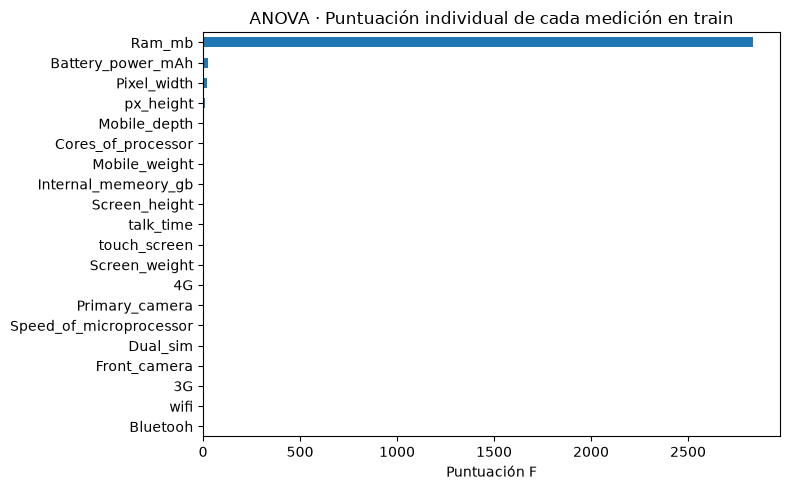

In [212]:
anova_scores.sort_values().plot.barh(figsize=(8, 5))
plt.title("ANOVA · Puntuación individual de cada medición en train")
plt.xlabel("Puntuación F")
plt.tight_layout()
plt.show()

----------------------------------------------------------------------------------------------

## 4. Selección hacia adelante . Forward selection

In [213]:
selection_model = Pipeline([
    ("scale", StandardScaler()),
    ("svc", SVC(kernel="rbf", C=1)),
])

selection_cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=RANDOM_STATE,
)

forward_selector = SequentialFeatureSelector(
    selection_model,
    n_features_to_select="auto",
    tol=1e-6,
    direction="forward",
    scoring="accuracy",
    cv=selection_cv,
)

forward_selector.fit(X_train, y_train)

,estimator estimator: estimator instanceAn unfitted estimator.,"Pipeline(step...', SVC(C=1))])"
,"tol tol: float, default=NoneIf the score is not incremented by at least `tol` between twoconsecutive feature additions or removals, stop adding or removing.`tol` can be negative when removing features using `direction=""backward""`.`tol` is required to be strictly positive when doing forward selection.It can be useful to reduce the number of features at the cost of a smalldecrease in the score.`tol` is enabled only when `n_features_to_select` is `""auto""`... versionadded:: 1.1",1e-06
,"scoring scoring: str or callable, default=NoneScoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)`` that returns a single value. See :ref:`scoring_callable` for details.- `None`: the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=5Determines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. In all othercases, :class:`~sklearn.model_selection.KFold` is used. These splittersare instantiated with `shuffle=False` so the splits will be the sameacross calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",StratifiedKFo... shuffle=True)
,"n_features_to_select n_features_to_select: ""auto"", int or float, default=""auto""If `""auto""`, the behaviour depends on the `tol` parameter:- if `tol` is not `None`, then features are selected while the score change does not exceed `tol`.- otherwise, half of the features are selected.If integer, the parameter is the absolute number of features to select.If float between 0 and 1, it is the fraction of features to select... versionadded:: 1.1 The option `""auto""` was added in version 1.1... versionchanged:: 1.3 The default changed from `""warn""` to `""auto""` in 1.3.",'auto'
,"direction direction: {'forward', 'backward'}, default='forward'Whether to perform forward selection or backward selection.",'forward'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel. When evaluating a new feature toadd or remove, the cross-validation procedure is parallel over thefolds.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](20,)","['Battery_power_mAh','Bluetooh','Speed_of_microprocessor',...,'3G', 'touch_screen','wifi']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,20
n_features_to_select_ n_features_to_select_: intThe number of features that were selected.,int64,np.int64(4)


In [214]:
selected_columns_forward = X_train.columns[forward_selector.get_support()].tolist()
selected_columns_forward

['Battery_power_mAh', 'px_height', 'Pixel_width', 'Ram_mb']

-----------------------------------------------------------------------------------------------

## 5. Selección hacia atrás . Backward elimination

In [215]:
backward_selector = SequentialFeatureSelector(
    selection_model,
    n_features_to_select="auto",
    tol=0.0,
    direction="backward",
    scoring="accuracy",
    cv=selection_cv,
)

backward_selector.fit(X_train, y_train)

,estimator estimator: estimator instanceAn unfitted estimator.,"Pipeline(step...', SVC(C=1))])"
,"tol tol: float, default=NoneIf the score is not incremented by at least `tol` between twoconsecutive feature additions or removals, stop adding or removing.`tol` can be negative when removing features using `direction=""backward""`.`tol` is required to be strictly positive when doing forward selection.It can be useful to reduce the number of features at the cost of a smalldecrease in the score.`tol` is enabled only when `n_features_to_select` is `""auto""`... versionadded:: 1.1",0.0
,"direction direction: {'forward', 'backward'}, default='forward'Whether to perform forward selection or backward selection.",'backward'
,"scoring scoring: str or callable, default=NoneScoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)`` that returns a single value. See :ref:`scoring_callable` for details.- `None`: the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=5Determines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. In all othercases, :class:`~sklearn.model_selection.KFold` is used. These splittersare instantiated with `shuffle=False` so the splits will be the sameacross calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",StratifiedKFo... shuffle=True)
,"n_features_to_select n_features_to_select: ""auto"", int or float, default=""auto""If `""auto""`, the behaviour depends on the `tol` parameter:- if `tol` is not `None`, then features are selected while the score change does not exceed `tol`.- otherwise, half of the features are selected.If integer, the parameter is the absolute number of features to select.If float between 0 and 1, it is the fraction of features to select... versionadded:: 1.1 The option `""auto""` was added in version 1.1... versionchanged:: 1.3 The default changed from `""warn""` to `""auto""` in 1.3.",'auto'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel. When evaluating a new feature toadd or remove, the cross-validation procedure is parallel over thefolds.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](20,)","['Battery_power_mAh','Bluetooh','Speed_of_microprocessor',...,'3G', 'touch_screen','wifi']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,20
n_features_to_select_ n_features_to_select_: intThe number of features that were selected.,int64,np.int64(16)


In [216]:
selected_columns_backward = X_train.columns[backward_selector.get_support()].tolist()
selected_columns_backward

['Battery_power_mAh',
 'Bluetooh',
 'Speed_of_microprocessor',
 'Dual_sim',
 'Front_camera',
 '4G',
 'Internal_memeory_gb',
 'Mobile_weight',
 'Cores_of_processor',
 'Primary_camera',
 'px_height',
 'Pixel_width',
 'Ram_mb',
 'Screen_weight',
 'touch_screen',
 'wifi']

Comparamos las listas. Convertirlas a `set` permite ver sus coincidencias y diferencias.


In [217]:
print("En ambos:", sorted(set(selected_columns_forward) & set(selected_columns_backward)))
print("Solo forward:", sorted(set(selected_columns_forward) - set(selected_columns_backward)))
print("Solo backward:", sorted(set(selected_columns_backward) - set(selected_columns_forward)))

En ambos: ['Battery_power_mAh', 'Pixel_width', 'Ram_mb', 'px_height']
Solo forward: []
Solo backward: ['4G', 'Bluetooh', 'Cores_of_processor', 'Dual_sim', 'Front_camera', 'Internal_memeory_gb', 'Mobile_weight', 'Primary_camera', 'Screen_weight', 'Speed_of_microprocessor', 'touch_screen', 'wifi']


--------------------------------------------

## 6. Eliminación recursiva . RFE

In [218]:
selection_scaler = StandardScaler()
X_train_scaled = selection_scaler.fit_transform(X_train)

rfe_selector = RFE(
    estimator=SVC(kernel="linear", C=1),
    n_features_to_select=5,
    step=1,
)

rfe_selector.fit(X_train_scaled, y_train)

,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).","SVC(C=1, kernel='linear')"
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",5
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",1
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only available when `estimator` is a classifier.","ndarray[int64](4,)","[0,1,2,3]"
estimator_ estimator_: ``Estimator`` instanceThe fitted estimator used to select features.,SVC,"SVC(C=1, kernel='linear')"
n_features_ n_features_: intThe number of selected features.,int64,np.int64(5)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,20
"ranking_ ranking_: ndarray of shape (n_features,)The feature ranking, such that ``ranking_[i]`` corresponds to theranking position of the i-th feature. Selected (i.e., estimatedbest) features are assigned rank 1.","ndarray[int64](20,)","[ 1, 5,11,..., 8,12, 3]"


In [219]:
selected_columns_rfe = X_train.columns[rfe_selector.get_support()].tolist()
selected_columns_rfe

['Battery_power_mAh', 'Mobile_weight', 'px_height', 'Pixel_width', 'Ram_mb']

El rango `1` identifica las variables conservadas. Los demás rangos corresponden a variables descartadas.


In [220]:
rfe_ranking = pd.Series(rfe_selector.ranking_, index=X_train.columns)
rfe_ranking.sort_values()

Battery_power_mAh           1
Ram_mb                      1
px_height                   1
Mobile_weight               1
Pixel_width                 1
Internal_memeory_gb         2
wifi                        3
Screen_height               4
Bluetooh                    5
Mobile_depth                6
4G                          7
3G                          8
Screen_weight               9
Primary_camera             10
Speed_of_microprocessor    11
touch_screen               12
Dual_sim                   13
talk_time                  14
Cores_of_processor         15
Front_camera               16
dtype: int64

-----------------------------------------------------------------------------

## 7. Selección con Lasso

In [221]:
class_indicators = pd.get_dummies(y_train, prefix="clase", dtype=int)
class_indicators.head()

,clase_0,clase_1,clase_2,clase_3
469,0,1,0,0
565,1,0,0,0
396,0,0,0,1
452,0,0,0,1
325,1,0,0,0


In [222]:
lasso = Lasso(alpha=0.05)
lasso.fit(X_train_scaled, class_indicators)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.05
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [223]:
lasso_weights = pd.DataFrame(lasso.coef_, index=class_indicators.columns, columns=X_train.columns)
lasso_weights.T

,clase_0,clase_1,clase_2,clase_3
Battery_power_mAh,-0.017929,-0.000000,-0.000000,0.031646
Bluetooh,0.000000,0.000000,-0.000000,0.000000
Speed_of_microprocessor,0.000000,-0.000000,0.000000,0.000000
Dual_sim,0.000000,-0.000000,-0.000000,0.000000
Front_camera,-0.000000,-0.000000,0.000000,-0.000000
4G,-0.000000,0.000000,-0.000000,0.000000
Internal_memeory_gb,-0.000000,0.000000,-0.000000,0.000000
Mobile_depth,-0.000000,0.000000,-0.000000,0.000000
Mobile_weight,0.000000,0.000000,0.000000,-0.000000
Cores_of_processor,0.000000,-0.000000,0.000000,-0.000000


Conservamos una característica si su coeficiente es distinto de cero en al menos una clase. En la siguiente celda, `.any()` comprueba esa condición para cada característica.


In [224]:
keep = (lasso_weights != 0).any()
selected_columns_lasso = X_train.columns[keep].tolist()
selected_columns_lasso

['Battery_power_mAh', 'px_height', 'Pixel_width', 'Ram_mb']

----------------------------------------------------------------------

## 8. Extensión: Búsqueda exhaustiva

In [225]:
def subset_accuracy(columns):
    scores = cross_val_score(
        selection_model, X_train[columns], y_train,
        cv=selection_cv, scoring="accuracy",
    )
    return scores.mean()

exhaustive_candidates = [
    "Ram_mb",
    "Battery_power_mAh",
    "px_height",
    "Pixel_width",
    "Internal_memeory_gb",
]
2 ** len(exhaustive_candidates) - 1

31


`combinations` construye los grupos de una, dos, tres, cuatro y cinco columnas.
Guardamos su puntuación para poder ver la tabla de resultados.

In [226]:
exhaustive_results = []

for size in range(1, len(exhaustive_candidates) + 1):
    for subset in combinations(exhaustive_candidates, size):
        columns = list(subset)
        score = subset_accuracy(columns)
        exhaustive_results.append({
            "columnas": columns,
            "variables": len(columns),
            "accuracy_cv": score,
        })

exhaustive_table = pd.DataFrame(exhaustive_results)
exhaustive_table = exhaustive_table.sort_values(
    ["accuracy_cv", "variables"], ascending=[False, True],
)
exhaustive_table.head()

,columnas,variables,accuracy_cv
25,"[Ram_mb, Battery_power_mAh, px_height, Pixel_w...",4,0.930625
30,"[Ram_mb, Battery_power_mAh, px_height, Pixel_w...",5,0.923126
15,"[Ram_mb, Battery_power_mAh, px_height]",3,0.895000
26,"[Ram_mb, Battery_power_mAh, px_height, Interna...",4,0.894375
16,"[Ram_mb, Battery_power_mAh, Pixel_width]",3,0.890000


In [227]:
selected_columns_exhaustive = exhaustive_table.iloc[0]["columnas"]
selected_columns_exhaustive

['Ram_mb', 'Battery_power_mAh', 'px_height', 'Pixel_width']

----------------------------------------------------------------

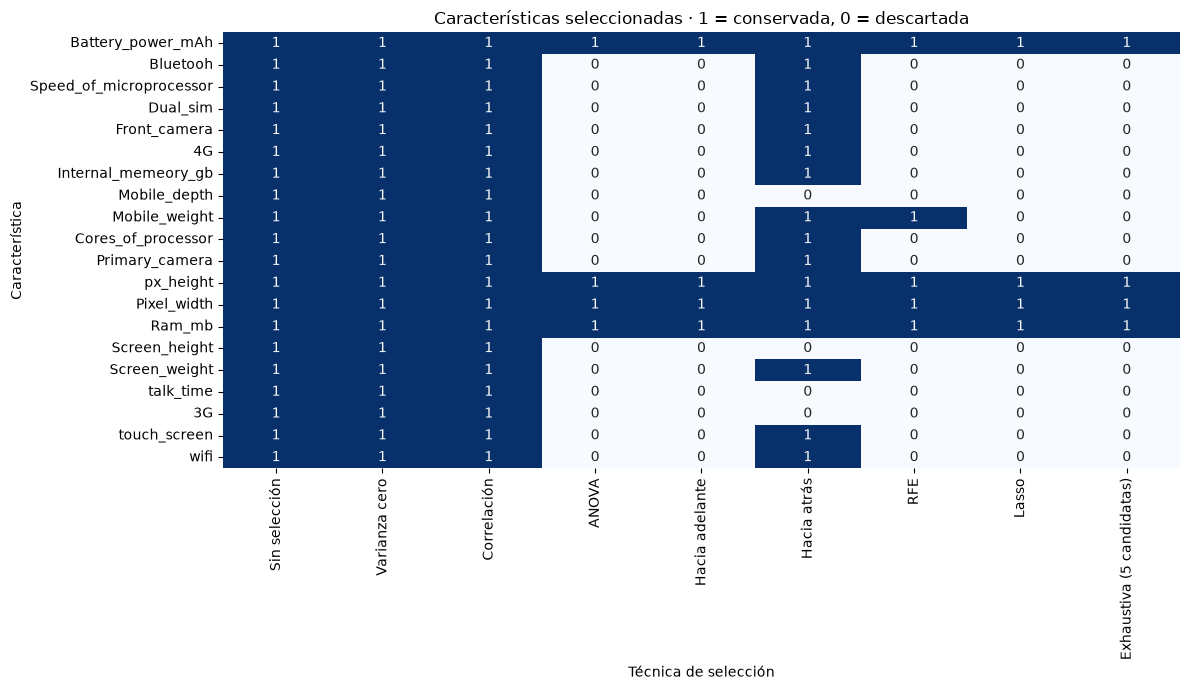

In [228]:
selected_columns_all = X_train.columns.tolist()

feature_sets = {
    "Sin selección": selected_columns_all,
    "Varianza cero": selected_columns_variance,
    "Correlación": selected_columns_correlation,
    "ANOVA": selected_columns_anova,
    "Hacia adelante": selected_columns_forward,
    "Hacia atrás": selected_columns_backward,
    "RFE": selected_columns_rfe,
    "Lasso": selected_columns_lasso,
    "Exhaustiva (5 candidatas)": selected_columns_exhaustive,
}

feature_matrix = pd.DataFrame(index=X_train.columns)

for method, columns in feature_sets.items():
    feature_matrix[method] = X_train.columns.isin(columns)

plt.figure(figsize=(12, 7))
sns.heatmap(
    feature_matrix.astype(int),
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
)
plt.title("Características seleccionadas · 1 = conservada, 0 = descartada")
plt.xlabel("Técnica de selección")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()

-----------------------------------------------------

## Entrenando con y sin Selección

In [232]:
particiones = list(selection_cv.split(X_train, y_train))

candidatos = [
    (
        "Random Forest", "passthrough",
        RandomForestClassifier(random_state=RANDOM_STATE),
        {"modelo__max_depth": [8, None]},
    ),
    (
        "KNN", StandardScaler(), KNeighborsClassifier(),
        {"modelo__n_neighbors": [5, 11]},
    ),
    (
        "SVC", StandardScaler(), SVC(),
        {"modelo__C": [1, 10]},
    ),
    (
        "Regresión logística", StandardScaler(),
        LogisticRegression(max_iter=2000),
        {"modelo__C": [1, 10]},
    ),
]

configuraciones = [
    ("Todas", "passthrough", X_train.shape[1]),
    ("ANOVA", SelectKBest(score_func=f_classif, k=4), 4),
]

resultados = []
busquedas = {}

for nombre, escalador, modelo, parametros in candidatos:
    for configuracion, selector, cantidad in configuraciones:
        pipeline = Pipeline([
            ("seleccion", selector),
            ("escalado", escalador),
            ("modelo", modelo),
        ])

        busqueda = GridSearchCV(
            pipeline, parametros, cv=particiones, scoring="accuracy"
        )
        busqueda.fit(X_train, y_train)
        busquedas[nombre, configuracion] = busqueda

        resultados.append({
            "modelo": nombre,
            "configuracion": configuracion,
            "caracteristicas": cantidad,
            "accuracy_cv": busqueda.best_score_,
        })

resultados = pd.DataFrame(resultados)

tabla = resultados.pivot(
    index="modelo",
    columns="configuracion",
    values="accuracy_cv",
)[["Todas", "ANOVA"]]

tabla.columns = ["20 características", "ANOVA (4 características)"]

print("Accuracy media de validación cruzada (3 particiones)")
display(tabla.round(4))

Accuracy media de validación cruzada (3 particiones)


,20 características,ANOVA (4 características)
modelo,,
KNN,0.5244,0.8869
Random Forest,0.8631,0.9050
Regresión logística,0.9562,0.9544
SVC,0.8450,0.9306


## Evaluar la configuración ganadora

Validación cruzada · partición 1 de 5
Validación cruzada · partición 2 de 5
Validación cruzada · partición 3 de 5
Validación cruzada · partición 4 de 5
Validación cruzada · partición 5 de 5
Accuracy media de validación cruzada (5 particiones)


modelo,N.º de características,Random Forest,KNN,SVC,Regresión logística
metodo,,,,,
Sin selección,20,0.8612,0.5412,0.8575,0.9631
Varianza cero,20,0.8612,0.5412,0.8575,0.9631
Correlación,20,0.8612,0.5412,0.8575,0.9631
ANOVA,4,0.9062,0.8819,0.9331,0.9500
Hacia adelante,4–5,0.9069,0.8744,0.9356,0.9550
Hacia atrás,4–14,0.8850,0.7662,0.9038,0.9606
RFE,5,0.9069,0.8469,0.9406,0.9688
Lasso,4,0.9062,0.8819,0.9331,0.9500
Exhaustiva (5 candidatas),4,0.9056,0.8819,0.9331,0.9500


Random Forest + Hacia adelante · Accuracy media: 90.69%
Hiperparámetros: {'modelo__max_depth': None}


KNN + ANOVA · Accuracy media: 88.19%
Hiperparámetros: {'modelo__n_neighbors': 11}


SVC + RFE · Accuracy media: 94.06%
Hiperparámetros: {'modelo__C': 10}


Regresión logística + RFE · Accuracy media: 96.88%
Hiperparámetros: {'modelo__C': 10}


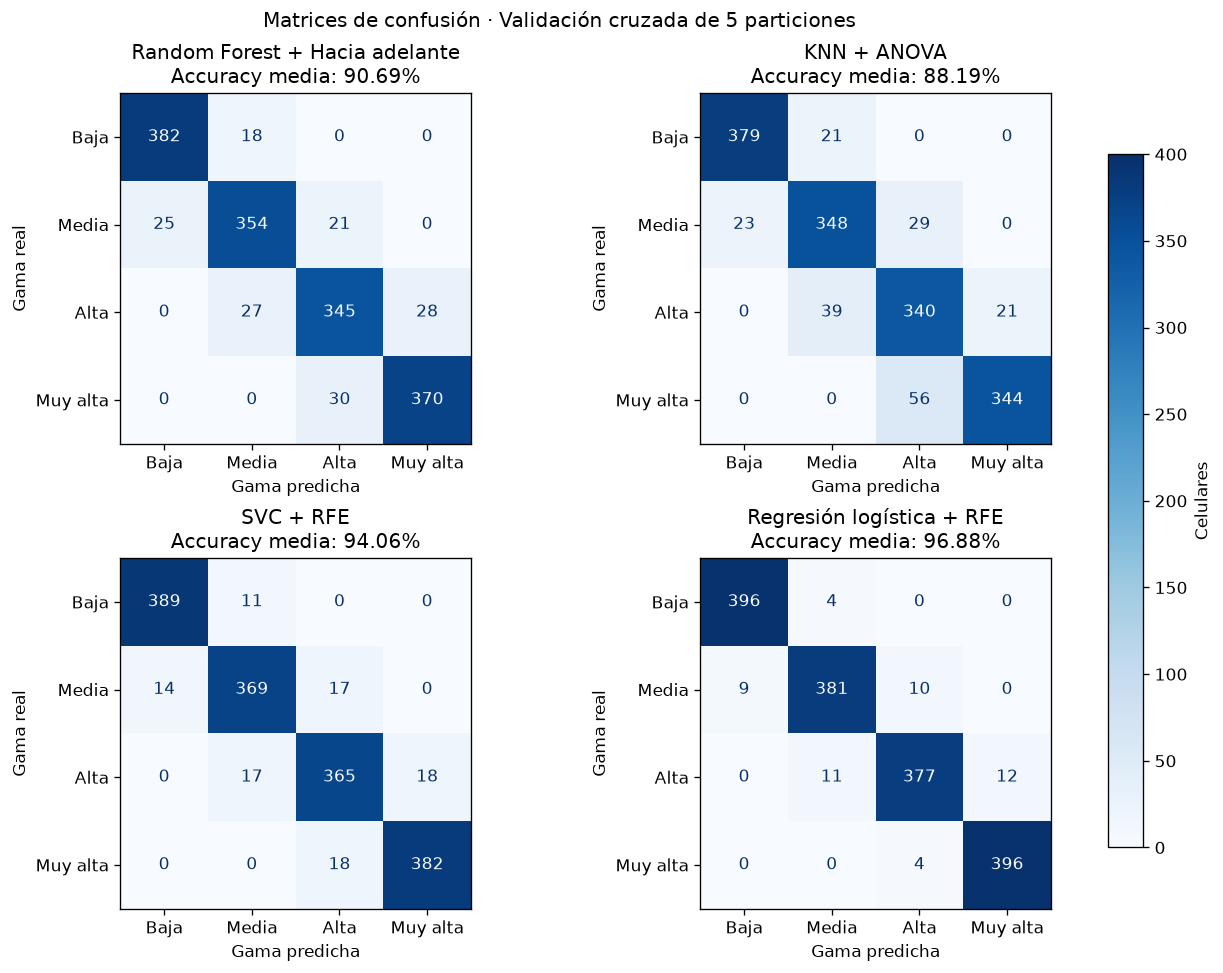

In [230]:
from sklearn.base import clone
from sklearn.model_selection import ParameterGrid


def seleccionar_columnas_cv(X_fold, y_fold):
    columnas = X_fold.columns
    grupos = {"Sin selección": columnas.tolist()}

    selectores = [
        ("Varianza cero", variance_selector),
        ("ANOVA", anova_selector),
        ("Hacia adelante", forward_selector),
        ("Hacia atrás", backward_selector),
    ]

    for nombre, selector in selectores:
        ajustado = clone(selector).fit(X_fold, y_fold)
        grupos[nombre] = columnas[ajustado.get_support()].tolist()

    correlaciones = X_fold.corr().abs()
    por_correlacion = []

    for columna in columnas:
        if (correlaciones.loc[columna, por_correlacion] < 0.85).all():
            por_correlacion.append(columna)

    grupos["Correlación"] = por_correlacion

    X_escalado = StandardScaler().fit_transform(X_fold)

    rfe_fold = clone(rfe_selector).fit(X_escalado, y_fold)
    grupos["RFE"] = columnas[rfe_fold.get_support()].tolist()

    clases = pd.get_dummies(y_fold, dtype=int)
    lasso_fold = clone(lasso).fit(X_escalado, clases)
    grupos["Lasso"] = columnas[(lasso_fold.coef_ != 0).any(axis=0)].tolist()

    mejor_accuracy = -np.inf

    for cantidad in range(1, len(exhaustive_candidates) + 1):
        for combinacion in combinations(exhaustive_candidates, cantidad):
            subconjunto = list(combinacion)
            accuracy = cross_val_score(
                selection_model,
                X_fold[subconjunto],
                y_fold,
                cv=selection_cv,
                scoring="accuracy",
            ).mean()

            if accuracy > mejor_accuracy:
                mejor_accuracy = accuracy
                grupos["Exhaustiva (5 candidatas)"] = subconjunto

    return grupos


cv_ampliada = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)
particiones_5 = list(cv_ampliada.split(X_train, y_train))
puntajes = []

for numero, (idx_ajuste, idx_val) in enumerate(particiones_5, start=1):
    print(f"Validación cruzada · partición {numero} de {len(particiones_5)}")

    X_ajuste, X_val = X_train.iloc[idx_ajuste], X_train.iloc[idx_val]
    y_ajuste, y_val = y_train.iloc[idx_ajuste], y_train.iloc[idx_val]
    grupos = seleccionar_columnas_cv(X_ajuste, y_ajuste)

    for metodo, columnas in grupos.items():
        for nombre, escalador, modelo, grilla in candidatos:
            pipeline = Pipeline([
                ("escalado", escalador),
                ("modelo", modelo),
            ])

            for opcion, parametros in enumerate(ParameterGrid(grilla)):
                ajustado = clone(pipeline).set_params(**parametros)
                ajustado.fit(X_ajuste[columnas], y_ajuste)
                predicciones = ajustado.predict(X_val[columnas])

                puntajes.append({
                    "metodo": metodo,
                    "modelo": nombre,
                    "opcion": opcion,
                    "n_columnas": len(columnas),
                    "accuracy": accuracy_score(y_val, predicciones),
                    "matriz_cv": confusion_matrix(y_val, predicciones, labels=[0, 1, 2, 3]),
                })

puntajes_cv = pd.DataFrame(puntajes)

# Promediar las cinco particiones para cada opción de hiperparámetro.
promedios = (
    puntajes_cv
    .groupby(["metodo", "modelo", "opcion"])["accuracy"]
    .mean()
)

# Mostrar el mejor promedio de cada combinación de método y modelo.
tabla_todos_metodos = (
    promedios.groupby(level=["metodo", "modelo"])
    .max()
    .unstack("modelo")
    .reindex(
        index=list(feature_sets),
        columns=[nombre for nombre, *_ in candidatos],
    )
)

conteo = (
    puntajes_cv.groupby("metodo")["n_columnas"]
    .agg(["min", "max"])
    .reindex(tabla_todos_metodos.index)
)

cantidades = [
    str(minimo) if minimo == maximo else f"{minimo}–{maximo}"
    for minimo, maximo in conteo.itertuples(index=False, name=None)
]

tabla_con_columnas = tabla_todos_metodos.copy()
tabla_con_columnas.insert(0, "N.º de características", cantidades)

print("Accuracy media de validación cruzada (5 particiones)")
display(tabla_con_columnas.round(4))

ranking_modelos = promedios.rename("accuracy_cv").reset_index()
cantidad_media = puntajes_cv.groupby("metodo")["n_columnas"].mean()
ranking_modelos["n_columnas_media"] = ranking_modelos["metodo"].map(cantidad_media)

mejor_por_modelo = (
    ranking_modelos
    .sort_values(
        ["accuracy_cv", "n_columnas_media", "metodo"],
        ascending=[False, True, True],
    )
    .drop_duplicates("modelo")
    .set_index("modelo")
)

gamas = ["Baja", "Media", "Alta", "Muy alta"]
confusiones_validacion = []

for nombre, _, _, grilla in candidatos:
    elegido = mejor_por_modelo.loc[nombre]
    metodo = elegido["metodo"]
    opcion = int(elegido["opcion"])
    parametros = list(ParameterGrid(grilla))[opcion]

    filas = puntajes_cv[
        (puntajes_cv["modelo"] == nombre)
        & (puntajes_cv["metodo"] == metodo)
        & (puntajes_cv["opcion"] == opcion)
    ]

    # Sumar las matrices de las cinco particiones de validación.
    matriz_total = np.stack(filas["matriz_cv"].tolist()).sum(axis=0)

    print(f"{nombre} + {metodo} · Accuracy media: {elegido['accuracy_cv']:.2%}")
    print("Hiperparámetros:", parametros)

    titulo = f"{nombre} + {metodo}\nAccuracy media: {elegido['accuracy_cv']:.2%}"
    confusiones_validacion.append((titulo, matriz_total))

fig, ejes = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
limite_color = max(matriz.sum(axis=1).max() for _, matriz in confusiones_validacion)

for eje, (titulo, matriz_total) in zip(ejes.flat, confusiones_validacion):
    grafica = ConfusionMatrixDisplay(
        confusion_matrix=matriz_total,
        display_labels=gamas,
    ).plot(
        ax=eje,
        cmap="Blues",
        values_format="d",
        colorbar=False,
        im_kw={"vmin": 0, "vmax": limite_color},
    )
    eje.set(title=titulo, xlabel="Gama predicha", ylabel="Gama real")

fig.colorbar(grafica.im_, ax=ejes.ravel(), label="Celulares", shrink=0.85)
fig.suptitle("Matrices de confusión · Validación cruzada de 5 particiones")
plt.show()

Configuración ganadora: Regresión logística + RFE
Accuracy media de validación: 96.88%
Mejores parámetros: {'modelo__C': 10}
Características utilizadas: ['Battery_power_mAh', 'Mobile_weight', 'px_height', 'Pixel_width', 'Ram_mb']
Aciertos en prueba: 393 de 400 (98.2%)


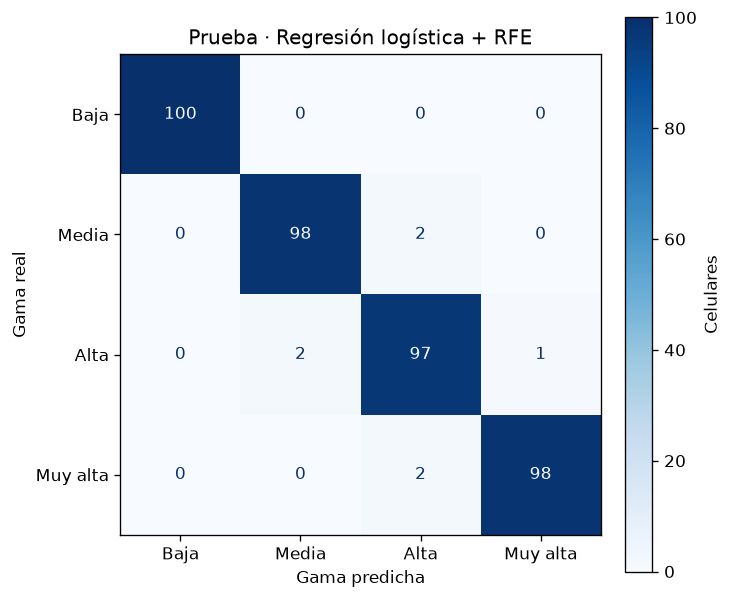

Error más frecuente: Media → Alta (2 celulares)
Error más frecuente: Alta → Media (2 celulares)
Error más frecuente: Muy alta → Alta (2 celulares)


In [231]:
ranking = promedios.rename("accuracy_cv").reset_index()
cantidad_media = puntajes_cv.groupby("metodo")["n_columnas"].mean()
ranking["n_columnas"] = ranking["metodo"].map(cantidad_media)

ganador = ranking.sort_values(
    ["accuracy_cv", "n_columnas"], ascending=[False, True]
).iloc[0]

metodo_ganador = ganador["metodo"]
modelo_ganador = ganador["modelo"]

_, escalador, modelo, grilla = next(
    candidato for candidato in candidatos if candidato[0] == modelo_ganador
)
parametros = list(ParameterGrid(grilla))[int(ganador["opcion"])]

# Estas columnas ya se eligieron usando todo el entrenamiento.
columnas_finales = feature_sets[metodo_ganador]

modelo_final = clone(Pipeline([
    ("escalado", escalador),
    ("modelo", modelo),
])).set_params(**parametros)

modelo_final.fit(X_train[columnas_finales], y_train)
y_pred = modelo_final.predict(X_test[columnas_finales])

aciertos = (y_test == y_pred).sum()
print(f"Configuración ganadora: {modelo_ganador} + {metodo_ganador}")
print(f"Accuracy media de validación: {ganador['accuracy_cv']:.2%}")
print("Mejores parámetros:", parametros)
print("Características utilizadas:", columnas_finales)
print(f"Aciertos en prueba: {aciertos} de {len(y_test)} ({aciertos / len(y_test):.1%})")

gamas = ["Baja", "Media", "Alta", "Muy alta"]
matriz = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3])

fig, eje = plt.subplots(figsize=(6, 5), layout="constrained")
grafica = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=gamas,
).plot(
    ax=eje,
    cmap="Blues",
    values_format="d",
    colorbar=False,
    im_kw={"vmin": 0, "vmax": matriz.sum(axis=1).max()},
)
eje.set(
    title=f"Prueba · {modelo_ganador} + {metodo_ganador}",
    xlabel="Gama predicha",
    ylabel="Gama real",
)
fig.colorbar(grafica.im_, ax=eje, label="Celulares")
plt.show()

errores = matriz.copy()
np.fill_diagonal(errores, 0)
maximo = errores.max()

if maximo > 0:
    for real, predicha in np.argwhere(errores == maximo):
        print(f"Error más frecuente: {gamas[real]} → {gamas[predicha]} ({maximo} celulares)")